# QFAMES numerical experiments
Run the three experiments and inspect their data and seven figures in one place.

Place this notebook in the repository root, beside `README.md`, `experiments/`, and `configs/`. Select a Python environment with the project dependencies installed. Run the cells from top to bottom, or use **Run All**.

The default is to **read saved paper data and regenerate figures without simulation**. Each experiment has its own action selector in its code cell: set it to `"run"` to compute or resume that experiment. For a short check, change `MODE` to `"quick"` below. Full runs can take considerable time and memory. This notebook calls the existing experiment modules in separate Python processes, so it also supports their multiprocessing implementation on Windows.

The notebook is supplied without experimental outputs. Figures displayed after execution are embedded in the saved notebook; the original CSV, JSON, PDF, and PNG files remain under `results/`.


In [24]:
from pathlib import Path
import csv
import html
import json
import os
import signal
import subprocess
import sys

from IPython.display import HTML, Image, Markdown, FileLink, display

# Usually no change is needed. Set an absolute path if Jupyter starts elsewhere.
PROJECT_ROOT = None

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates
                 if (p / "experiments/common.py").is_file()
                 and (p / "qfames/core.py").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("Open this notebook from the repository, or set PROJECT_ROOT.")
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
    if not (ROOT / "experiments/common.py").is_file():
        raise FileNotFoundError(f"Not a QFAMES repository: {ROOT}")

print("Project:", ROOT)
print("Python:", sys.executable)


Project: c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling
Python: d:\ProgramFiles2\Anaconda3\envs\qfames\python.exe


## Run settings
- `MODE = "paper"`: use the JSON configurations; `"quick"`: use the scripts' small smoke-test settings.
- Set `EIGENVALUE_ACTION`, `MULTIPLICITY_ACTION`, and `OBSERVABLE_ACTION` independently in their experiment cells below. Each defaults to `"plot"`: read saved summaries and metadata, regenerate figures, and display results without simulation. Use `"run"` to compute or resume, then plot and display; `"view"` only displays existing results. Missing saved data is reported and skipped; it never starts a simulation automatically. The per-experiment `OUTPUTS` mapping below selects directories. Multiplicity defaults to `results/paper/multiplicity/`.
- `RESUME = True`: reuse completed trials; the scripts check configurations, source hashes, and NumPy/SciPy versions. Completed compatible runs do not repeat simulations. To rerun from scratch, choose a new `RUN_NAME` and set the desired experiment action to `"run"`.
- `RUN_NAME = None`: save to `results/paper/` or `results/quick/`. For changed settings, use a new name, e.g. `"paper-v2"`; do not overwrite an older run.
- `TRIALS` and `SEED`: leave as `None` to use defaults. Configurations can be edited in `configs/*.json`.

Do not run a terminal job and this notebook against the same output directory simultaneously. To inspect an active run, wait for it to finish: summaries and figures are normally written at the end.


In [25]:
MODE = "paper"
WORKERS = 2
RESUME = True
TRIALS = None
SEED = None
RUN_NAME = None

EXPERIMENTS = ("eigenvalue", "multiplicity", "observable")
CONFIGS = {name: ROOT / "configs" / f"{name}.json" for name in EXPERIMENTS}

if MODE not in {"paper", "quick"}:
    raise ValueError("MODE must be paper or quick.")
if not isinstance(WORKERS, int) or WORKERS < 1:
    raise ValueError("WORKERS must be a positive integer.")
if TRIALS is not None and (not isinstance(TRIALS, int) or TRIALS < 1):
    raise ValueError("TRIALS must be None or a positive integer.")
if SEED is not None and (not isinstance(SEED, int) or SEED < 0):
    raise ValueError("SEED must be None or a nonnegative integer.")
if RUN_NAME is not None and (not RUN_NAME or RUN_NAME in {".", ".."}
                             or "/" in RUN_NAME or "\\" in RUN_NAME):
    raise ValueError("RUN_NAME must be a single folder name.")

OUTPUT_ROOT = ROOT / "results" / (RUN_NAME or MODE)
print(f"Mode: {MODE}; workers: {WORKERS}")
print("Output:", OUTPUT_ROOT)

# Independent output directories; changing one does not redirect other experiments.
OUTPUTS = {
    "eigenvalue": OUTPUT_ROOT / "eigenvalue",
    "multiplicity": OUTPUT_ROOT / "multiplicity",
    "observable": OUTPUT_ROOT / "observable",
}


Mode: paper; workers: 2
Output: c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper


## Execution and display helpers
The child processes use the notebook kernel's Python interpreter. Output is streamed into the cell. Interrupting a running cell stops its experiment process tree; completed trial rows are retained for `RESUME=True`. An interrupted run may not yet have an updated summary or figure.

Errors from an experiment stop the notebook instead of silently displaying old figures. A configuration or version mismatch on resume requires the original settings or a new output directory.


In [26]:
FIGURES = {
    "eigenvalue": ["eigenvalue_error_vs_state_count", "eigenvalue_error_vs_total_time"],
    "multiplicity": ["multiplicity_singular_values_vs_state_count_independent",
                     "multiplicity_singular_values_vs_state_count_shared"],
    "observable": ["observable_error_vs_state_count", "observable_error_vs_total_time"],
}


def execute(command):
    env = os.environ.copy()
    env["PYTHONUNBUFFERED"] = "1"
    env["PYTHONIOENCODING"] = "utf-8"
    options = {"creationflags": subprocess.CREATE_NEW_PROCESS_GROUP} if os.name == "nt" else {"start_new_session": True}
    print("Running:", " ".join(str(part) for part in command), flush=True)
    process = subprocess.Popen(
        [str(part) for part in command], cwd=ROOT, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace", bufsize=1, **options,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
        if returncode:
            raise subprocess.CalledProcessError(returncode, command)
    except BaseException:
        if process.poll() is None:
            if os.name == "nt":
                subprocess.run(["taskkill", "/PID", str(process.pid), "/T", "/F"],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False)
            else:
                try:
                    os.killpg(process.pid, signal.SIGTERM)
                except ProcessLookupError:
                    pass
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                if os.name != "nt":
                    try:
                        os.killpg(process.pid, signal.SIGKILL)
                    except ProcessLookupError:
                        pass
                else:
                    process.kill()
                process.wait()
        raise
    finally:
        process.stdout.close()


def multiplicity_settings_match(name):
    if name != "multiplicity":
        return True
    meta = json.loads((OUTPUTS[name] / "metadata.json").read_text(encoding="utf-8"))
    current = json.loads(CONFIGS[name].read_text(encoding="utf-8"))
    if MODE == "quick":
        current.update(L_values=[4, 6, 8], N_values=[40, 80, 160], fixed_N=80, trials=4)
    if TRIALS is not None:
        current["trials"] = TRIALS
    if SEED is not None:
        current["seed"] = SEED
    if meta["config"] != current or meta.get("quick") != (MODE == "quick"):
        print("Existing results use outdated settings; rerun multiplicity")
        print("Saved settings:", meta["config"])
        print("Requested settings:", current)
        return False
    return True


def run_experiment(name, action="plot"):
    if action not in {"run", "plot", "view"}:
        raise ValueError(f"{name}: action must be run, plot, or view.")
    directory = OUTPUTS[name]
    if action in {"plot", "view"}:
        missing = [str(directory / filename) for filename in ("metadata.json", "summary.csv")
                   if not (directory / filename).is_file()]
        if missing:
            print(f"{name}: no saved data in {directory}; skipped. Explicitly select action=run to simulate.")
            return False
    if action in {"plot", "view"} and not multiplicity_settings_match(name):
        return False
    if action == "view":
        return True
    if action == "plot":
        execute([sys.executable, "-u", "-m", "qfames.plotting", directory])
        return True
    command = [sys.executable, "-u", "-m", f"experiments.{name}_scaling",
               "--config", CONFIGS[name], "--output", directory, "--workers", WORKERS]
    if MODE == "quick":
        command.append("--quick")
    if TRIALS is not None:
        command += ["--trials", TRIALS]
    if SEED is not None:
        command += ["--seed", SEED]
    if RESUME:
        command.append("--resume")
    execute(command)
    return True


def show_results(name):
    directory = OUTPUTS[name]
    required = [directory / "metadata.json", directory / "summary.csv"]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError("Run the experiment first. Missing: " + ", ".join(missing))
    if not multiplicity_settings_match(name):
        return
    meta = json.loads(required[0].read_text(encoding="utf-8"))
    with required[1].open(newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    cfg = meta["config"]
    display(Markdown(f"### {name.capitalize()} results"))
    print("Saved run:", directory)
    print(f"Saved settings: T={cfg['T']}, sigma={cfg['sigma']}, trials/point={cfg['trials']}, seed={cfg['seed']}")
    if meta.get("quick"):
        display(Markdown("**Smoke-test data: not paper results.**"))
    observed = sum(int(r["trials"]) for r in rows)
    failed = sum(int(r["failed"]) for r in rows)
    ns = [cfg["fixed_N"]] if name == "multiplicity" else cfg["N_values"]
    expected = len(cfg["L_values"]) * len(ns) * cfg["trials"] * len(meta.get("sampling_schemes", ["independent"] if name == "multiplicity" else ["independent", "shared"]))
    print(f"Trials in saved summary: {observed}/{expected}; failures: {failed}")
    if observed != expected:
        display(Markdown("**Partial summary: complete or resume this run before using its figures.**"))
    print("Summary and images reflect their last saved versions; an active run may be newer.")
    columns = ["scheme", "N", "L", "trials", "failed", "error_q90", "mean_total_time"]
    if name == "multiplicity":
        columns = ["scheme", "N", "L", "trials", "failed"] + [f"sv_{c}_{k}" for c in range(2) for k in range(1, 5)]
        print("sv_<cluster>_<k> columns contain mean normalized singular values s_k/L evaluated at the exact cluster centers.")
    def formatted(value):
        try:
            return f"{float(value):.5g}"
        except ValueError:
            return value
    header = "".join(f"<th>{html.escape(c)}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(formatted(row[c]))}</td>" for c in columns) + "</tr>" for row in rows)
    display(HTML(f'<div style="overflow-x:auto"><table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'))
    figures = directory / "figures"
    for stem in FIGURES[name]:
        if name == "multiplicity" and "singular_values" in stem:
            scheme = stem.rsplit("_", 1)[-1]
            if not any(r.get("scheme", "independent") == scheme for r in rows):
                print(f"No {scheme} data; singular-value figure skipped.")
                continue
        png = figures / f"{stem}.png"
        if not png.is_file():
            raise FileNotFoundError(f"Missing {png}; set this experiment action to 'plot' to regenerate figures.")
        display(Markdown(f"**{stem.replace('_', ' ')}**"))
        display(Image(filename=str(png), width=653 if "singular_values" in stem else 322))
        pdf = png.with_suffix(".pdf")
        if pdf.is_file():
            display(FileLink(os.path.relpath(pdf, Path.cwd())))
    for filename in ("metadata.json", "trials.csv", "summary.csv"):
        display(FileLink(os.path.relpath(directory / filename, Path.cwd())))


## 1. Eigenvalue error scaling
Two figures: error versus L=R, and error versus actual total evolution time. The cost plot contains three independent and three shared curves at fixed N.


Running: d:\ProgramFiles2\Anaconda3\envs\qfames\python.exe -u -m qfames.plotting c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue
Figures saved to c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\figures


### Eigenvalue results

Saved run: c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue
Saved settings: T=200.0, sigma=6.0, trials/point=100, seed=42
Trials in saved summary: 5400/5400; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.


scheme,N,L,trials,failed,error_q90,mean_total_time
independent,50,2,100,0,0.0012133,45030
independent,50,4,100,0,0.00058633,1.8002e+05
independent,50,8,100,0,0.00027417,7.2147e+05
independent,50,12,100,0,0.00018709,1.627e+06
independent,50,20,100,0,0.00012471,4.5078e+06
independent,50,32,100,0,6.4073e-05,1.155e+07
independent,50,50,100,0,4.4512e-05,2.8204e+07
independent,50,80,100,0,2.9396e-05,7.2228e+07
independent,50,110,100,0,2.1134e-05,1.3651e+08
independent,200,2,100,0,0.00049246,1.8079e+05


**eigenvalue error vs state count**

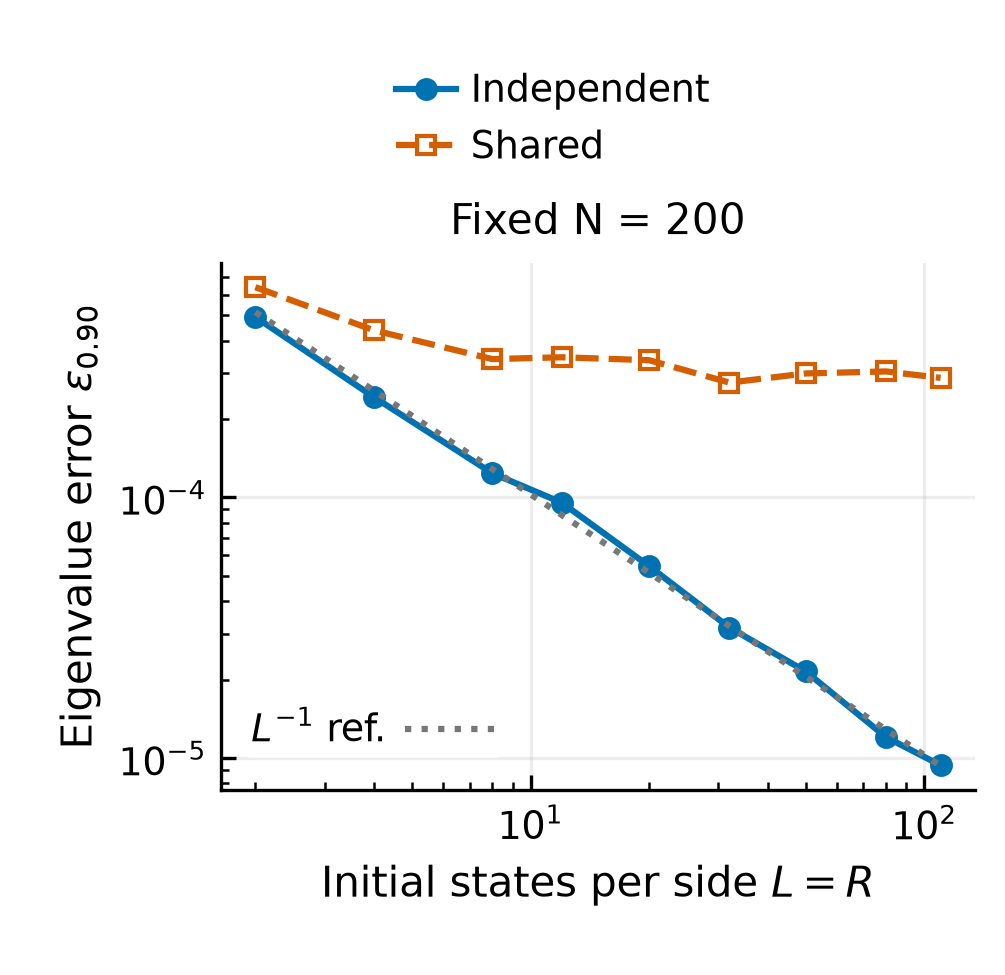

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\figures\eigenvalue_error_vs_state_count.pdf

**eigenvalue error vs total time**

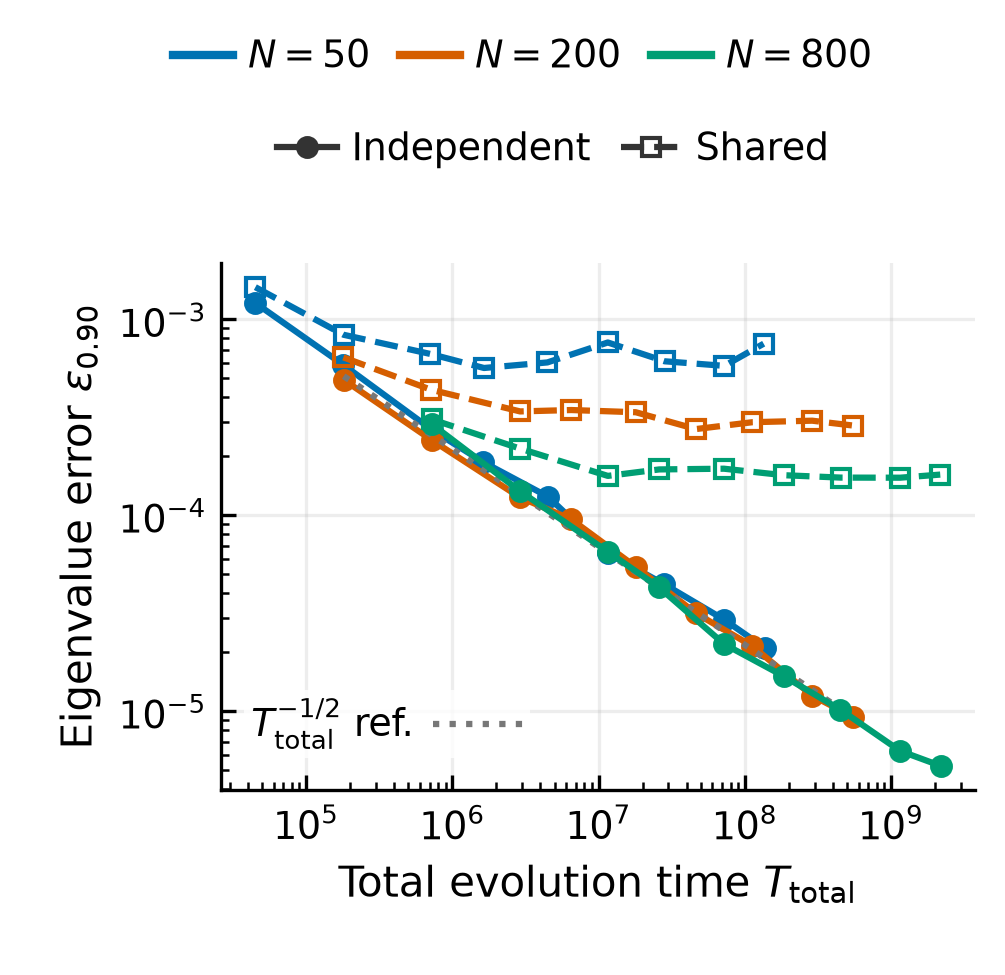

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\figures\eigenvalue_error_vs_total_time.pdf

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\metadata.json

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\trials.csv

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\eigenvalue\summary.csv

In [27]:
EIGENVALUE_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("eigenvalue", EIGENVALUE_ACTION):
    show_results("eigenvalue")


## 2. Multiplicity structure
Two separate 1x2 singular-value figures show independent and shared sampling. Each shows the trial-mean s1/L through s4/L only at the exact evaluation centers [0, 0.02], with target multiplicities 2 and 1. No peak search or thresholding is performed. The configured experiment uses spectrum=[0,0,0.02,0.10], random normalized four-dimensional initial states, min_overlap=0.4 and noise_std=0.1. The 0.10 spectral direction contributes to sampling but creates no third evaluation center or panel. T=150, sigma=6, N=500, L=R in [5,8,12,16,24,32,50,70,100], 50 trials and seed=42.

`grid_step`, `alpha`, `threshold`, and `search_bounds` are not used by this multiplicity diagnostic. Their use in other experiments is unchanged.

Both figures have y-axis limits [2e-3, 0.4]. Only independent shows the L^(-1/2) reference guide, using s4/L at L >= 24 when at least two valid points exist. The shared figure has no reference guide. A matching dotted line sample follows `ref.`.

SEM is calculated for every normalized singular value from the existing `trials.csv`, grouped by (scheme, N, L), as sample standard deviation (ddof=1) / sqrt(n). Thin +/-1 SEM error bars appear only on s4/L in both schemes; the mean curves remain from `summary.csv`. Error bars are omitted when SEM is undefined (fewer than two trials or nonfinite values).

Figures are saved in `multiplicity/figures/`; raw data remain in `multiplicity/`. Keep `MULTIPLICITY_ACTION = "plot"` to regenerate figures from saved data without simulation.

The longer filter time is intended to suppress deterministic leakage from other clusters below statistical noise, exposing the independent/shared difference in non-target singular values. Curves are not smoothed or adjusted. Saved settings are checked dynamically: a mismatch reports **Existing results use outdated settings; rerun multiplicity** and skips plotting/display. To replace results safely at the original path, follow the multiplicity-only backup and rerun commands in README; do not resume old settings.


Running: d:\ProgramFiles2\Anaconda3\envs\qfames\python.exe -u -m qfames.plotting c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity
Figures saved to c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\figures


### Multiplicity results

Saved run: c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity
Saved settings: T=150.0, sigma=6.0, trials/point=50, seed=42
Trials in saved summary: 900/900; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.
sv_<cluster>_<k> columns contain mean normalized singular values s_k/L evaluated at the exact cluster centers.


scheme,N,L,trials,failed,sv_0_1,sv_0_2,sv_0_3,sv_0_4,sv_1_1,sv_1_2,sv_1_3,sv_1_4
independent,500,5,50,0,0.30382,0.1732,0.0083511,0.0047378,0.25105,0.01244,0.0082767,0.0045788
independent,500,8,50,0,0.29809,0.18242,0.0085563,0.006668,0.24843,0.011562,0.0090223,0.0070775
independent,500,12,50,0,0.28912,0.20049,0.0078743,0.0067183,0.24859,0.0099915,0.0086223,0.0074792
independent,500,16,50,0,0.2845,0.20515,0.0073933,0.006363,0.25129,0.0089212,0.0080082,0.0071666
independent,500,24,50,0,0.28072,0.21492,0.0062272,0.0056653,0.24834,0.007694,0.0070206,0.0065087
independent,500,32,50,0,0.27959,0.21736,0.0055663,0.0051877,0.24873,0.0067265,0.0063061,0.0059597
independent,500,50,50,0,0.27314,0.22547,0.0045874,0.0043487,0.25109,0.0055057,0.0052426,0.0050156
independent,500,70,50,0,0.26865,0.23004,0.0039333,0.0037714,0.24924,0.0047191,0.0045326,0.0043971
independent,500,100,50,0,0.26662,0.23299,0.0033228,0.0032223,0.24944,0.003985,0.0038642,0.0037741
shared,500,5,50,0,0.30414,0.17341,0.0092415,0.0033407,0.25179,0.014565,0.0069359,0.0029562


**multiplicity singular values vs state count independent**

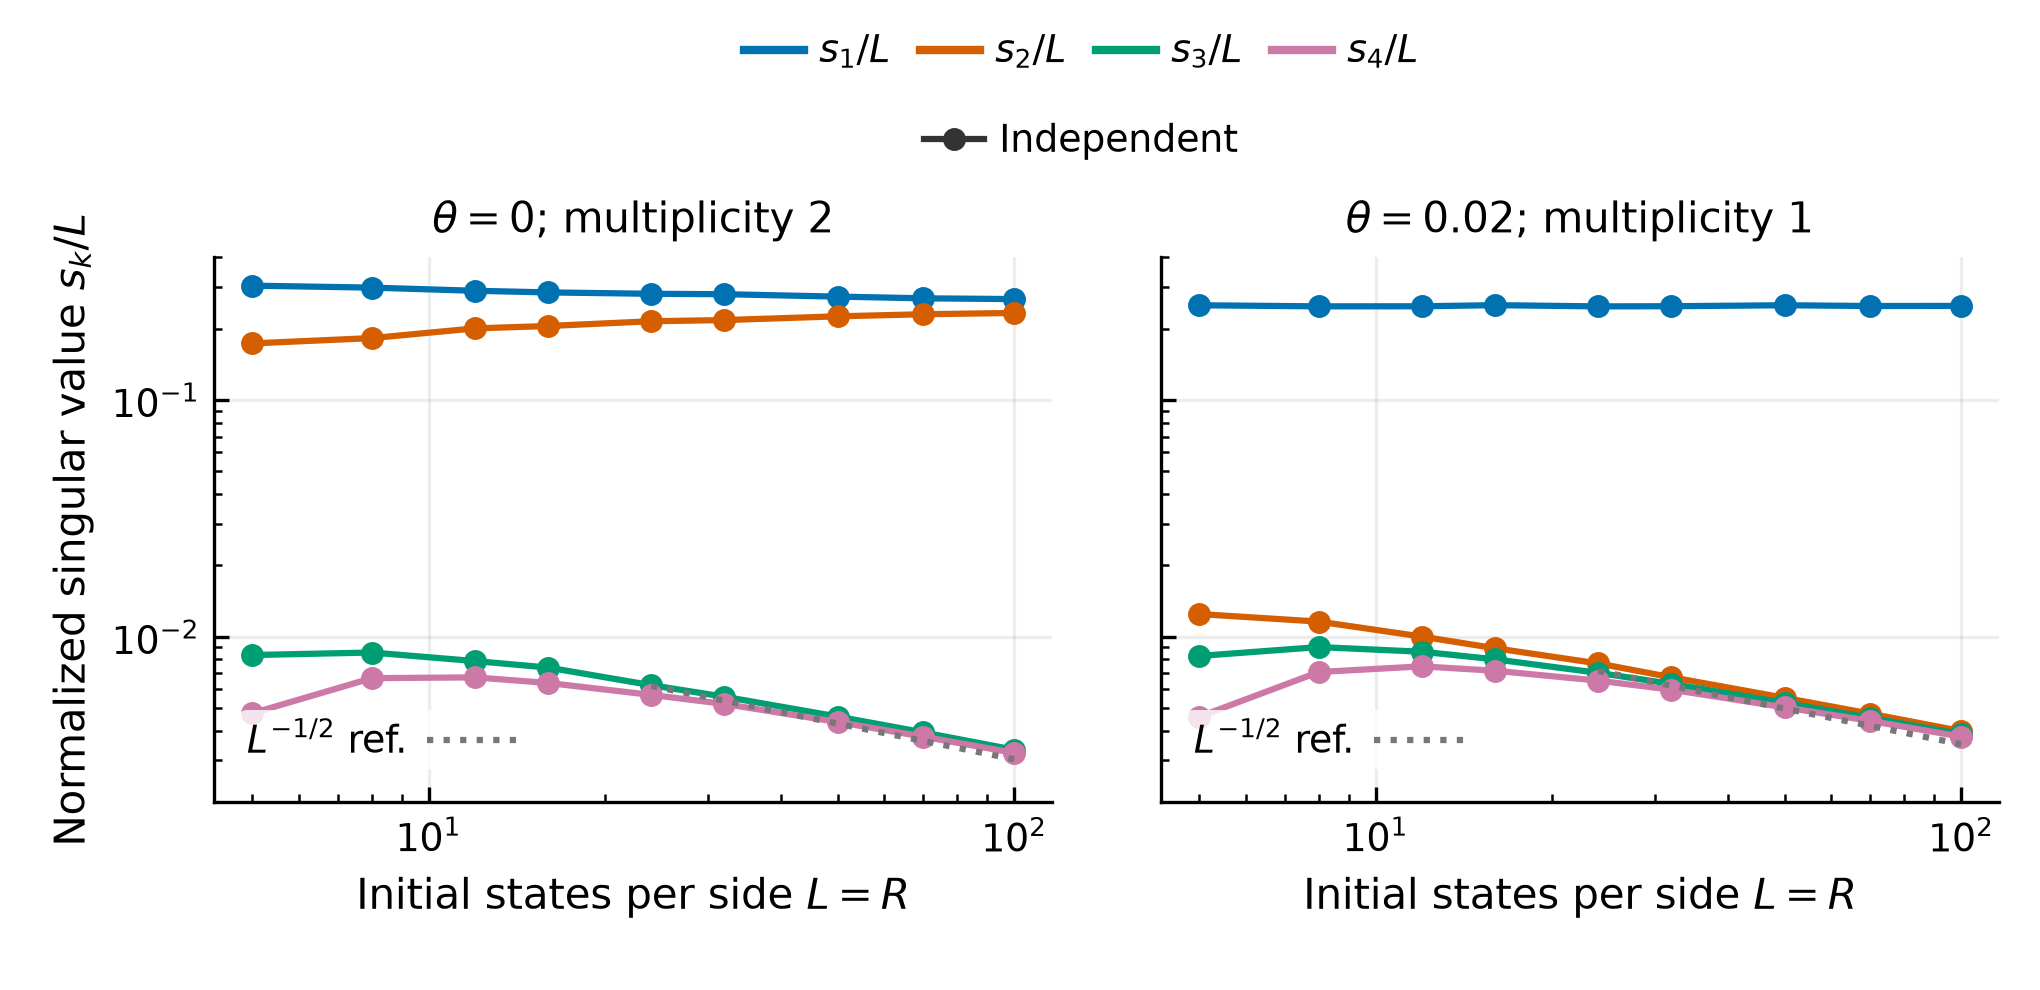

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\figures\multiplicity_singular_values_vs_state_count_independent.pdf

**multiplicity singular values vs state count shared**

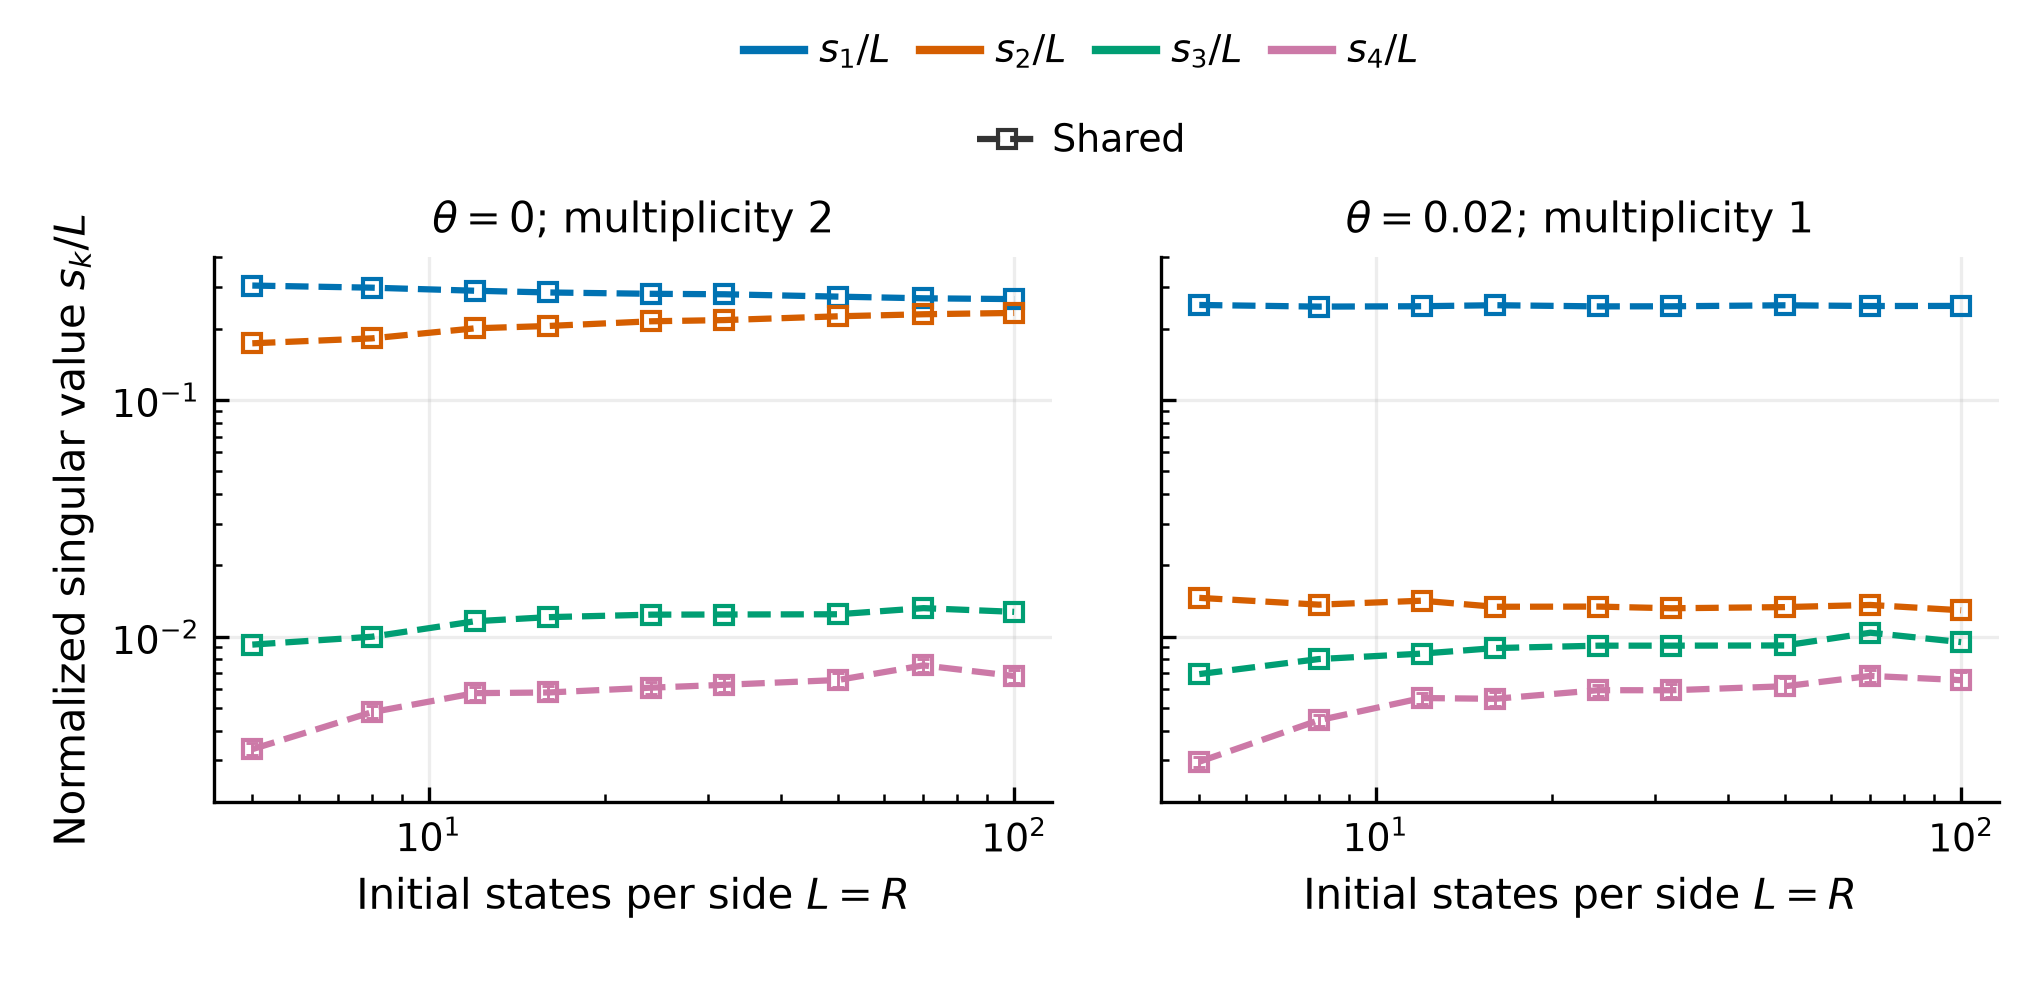

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\figures\multiplicity_singular_values_vs_state_count_shared.pdf

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\metadata.json

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\trials.csv

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\multiplicity\summary.csv

In [28]:
MULTIPLICITY_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("multiplicity", MULTIPLICITY_ACTION):
    show_results("multiplicity")


## 3. Observable error scaling
Two figures, comparing independent and shared sampling. Total cost includes spectral-data acquisition and both observable evolution legs.


Running: d:\ProgramFiles2\Anaconda3\envs\qfames\python.exe -u -m qfames.plotting c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable
Figures saved to c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\figures


### Observable results

Saved run: c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable
Saved settings: T=50.0, sigma=6.0, trials/point=100, seed=42
Trials in saved summary: 4800/4800; failures: 0
Summary and images reflect their last saved versions; an active run may be newer.


scheme,N,L,trials,failed,error_q90,mean_total_time
independent,200,3,100,0,0.073765,2.4547e+05
independent,200,5,100,0,0.04453,6.8086e+05
independent,200,8,100,0,0.028244,1.7448e+06
independent,200,12,100,0,0.016703,3.9201e+06
independent,200,16,100,0,0.014146,6.9734e+06
independent,200,24,100,0,0.010425,1.5688e+07
independent,200,32,100,0,0.0071948,2.7885e+07
independent,200,50,100,0,0.0040586,6.8098e+07
independent,500,3,100,0,0.045729,6.13e+05
independent,500,5,100,0,0.025984,1.7029e+06


**observable error vs state count**

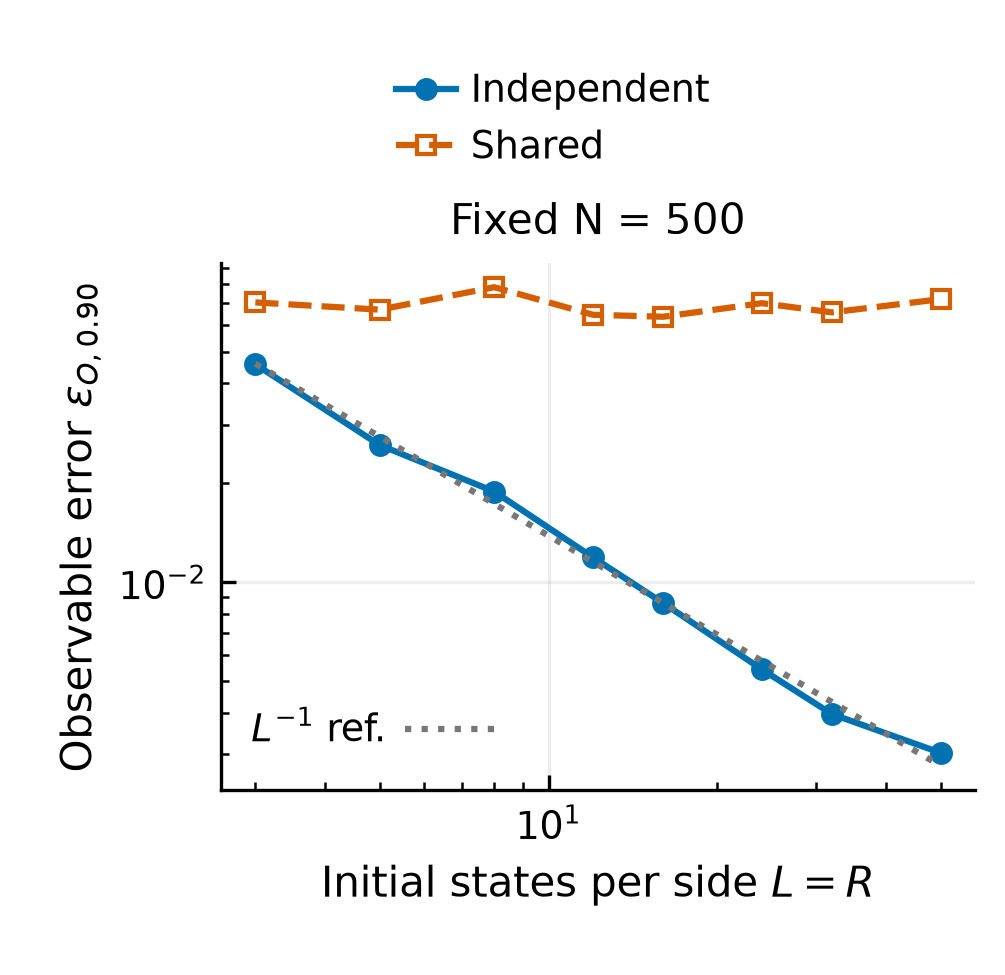

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\figures\observable_error_vs_state_count.pdf

**observable error vs total time**

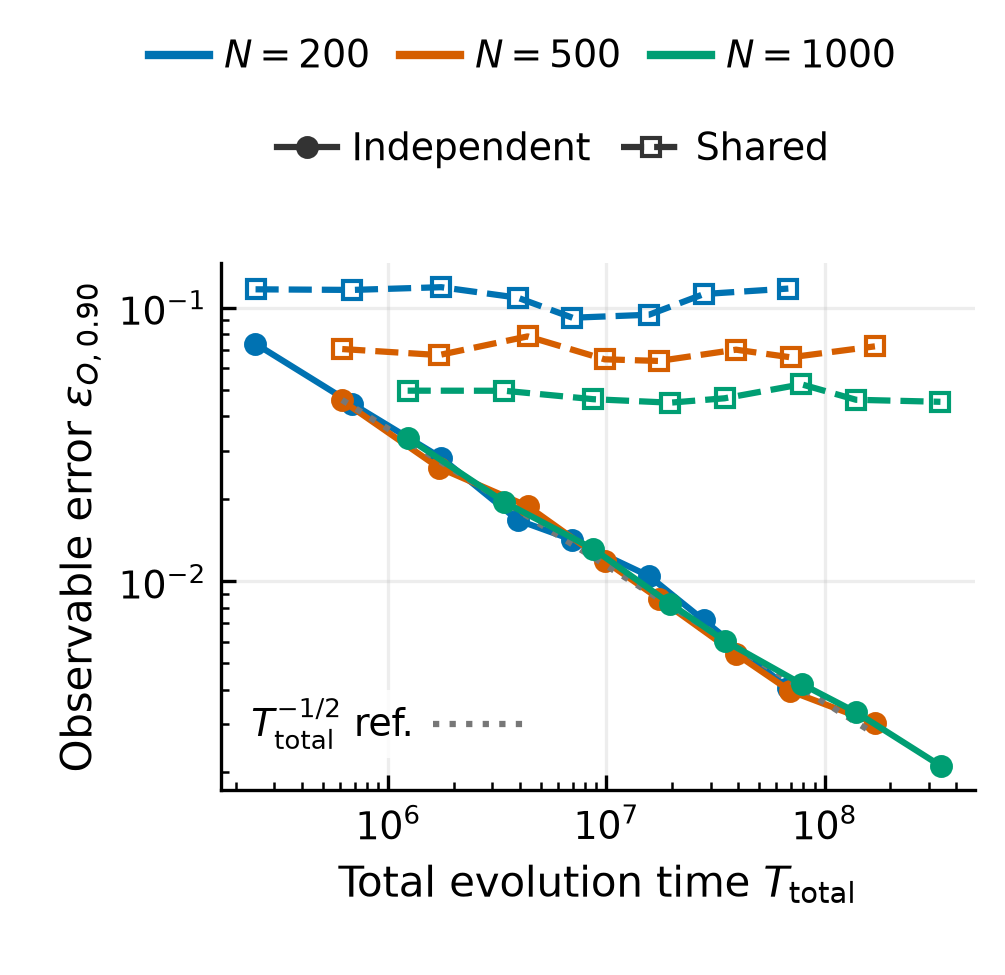

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\figures\observable_error_vs_total_time.pdf

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\metadata.json

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\trials.csv

c:\Users\HP\Desktop\Files\Research\DZY\work\qfames-error-scaling\results\paper\observable\summary.csv

In [29]:
OBSERVABLE_ACTION = "plot"  # "plot": read data and replot; "run": compute/resume; "view": display only

if run_experiment("observable", OBSERVABLE_ACTION):
    show_results("observable")


## Save and share
Save the notebook after a full run to retain its inline figures and tables for readers. Commit the notebook together with the matching code, configurations, and `results/paper/` data. Ignore `.ipynb_checkpoints/`, not the notebook itself.

To read data and regenerate figures without computation, leave each experiment action at its default `"plot"` and run all cells. Use `"view"` to display existing figures only. To change plot styling, edit `qfames/plotting.py` and rerun the desired experiment cells with action `"plot"`. This uses saved summaries and metadata. Multiplicity plotting/display is skipped with an explicit rerun message if the saved and requested configurations differ.

A custom `RUN_NAME` lies outside `results/paper/`; explicitly include that directory in Git if it becomes a paper result. Do not present quick-run outputs as paper figures.

Every reference label includes a matching dotted line sample after `ref.` to identify the guide clearly.
